# One epidemic, day by day: running the engine on a first case

**Question:** In a town of 100000 people where 50 are infected today and each infected person passes the disease to 2.75 others on average, how many are ill at the worst moment, on which day does that happen, and what share of the town has been infected by the end of the outbreak?

- **Level:** 1, Fundamentals
- **Prerequisites:** none, this is the entry notebook of the set
- **Reading time:** about 20 minutes

## Objectives

By the end of this notebook you can run the pipeline's engine on a case of the example, read the three curves it returns and the three numbers that summarise them, and say what happens to those numbers when one input changes. It is the entry of the set: the next notebook asks how far the engine's own arithmetic can be trusted, and the second topic explains why some outbreaks take off while others never do.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

In [2]:
# the five cases: contact rate, recovery rate, population, first infected people, horizon, and R0 = beta / gamma
print(f"{'case':18s} {'beta':>5s} {'gamma':>6s} {'N':>7s} {'I0':>4s} {'days':>5s} {'R0':>5s}")
for case_id in CASES:
    p = params_of(case_id)
    print(f"{case_id:18s} {p.beta:5.2f} {p.gamma:6.2f} {p.N:7.0f} {p.I0:4.0f} {p.days:5d} {p.beta / p.gamma:5.2f}")

case                beta  gamma       N   I0  days    R0
CTRL_degenerate     0.40   0.20  100000    0   160  2.00
EX01_subcritical    0.18   0.25  100000   50   160  0.72
EX02_epidemic       0.55   0.20  100000   50   160  2.75
EX03_fast_burn      1.20   0.20  100000  100   160  6.00
EX04_slow_spread    0.30   0.25  100000   50   160  1.20


## Method

The example models an epidemic in a closed population of $N$ people with the SIR system of Kermack and McKendrick (1927), the textbook model that Hethcote (2000) surveys. Each person is in one of three compartments: susceptible ($S$), infected ($I$) or recovered ($R$). Susceptible people become infected by meeting infected ones, and infected people recover:

$$\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad \frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

The contact rate $\beta$ (per day) is how many people one infected person reaches per day, and the recovery rate $\gamma$ (per day) is the inverse of the days a person stays infectious. The engine is the function `simulate` of `data-pipeline/pipeline/model/sir.py`. It starts from $I_0$ infected people and everybody else susceptible, and advances these equations a quarter of a day at a time. Three numbers summarise a run: the peak of $I$, the day of that peak, and the attack rate, the share of the population that has been infected by the end of the horizon.

Five cases are on file. The first question of the notebook is about the third one, `EX02_epidemic`, with $\beta = 0.55$ and $\gamma = 0.20$ per day, so that one infected person infects $\beta / \gamma = 2.75$ others over the time spent ill. The cell below asks the engine for that run and looks at what comes back, before drawing anything: how many points, and the first values of the three compartments. Look for two things: $S$ starts at $N - I_0$, and $I$ starts to grow from the first step.

In [3]:
# run the engine on the epidemic case and look at what it returns
p = params_of("EX02_epidemic")
result = simulate(p)
print(f"points: {len(result.t)}, from day {result.t[0]:.2f} to day {result.t[-1]:.2f}")
print("S", [round(v) for v in result.S[:4]])
print("I", [round(v, 1) for v in result.I[:4]])
print("R", [round(v, 1) for v in result.R[:4]])

points: 641, from day 0.00 to day 160.00
S [99950, 99943, 99936, 99928]
I [50.0, 54.4, 59.1, 64.3]
R [0.0, 2.5, 5.2, 8.2]


The engine returned 641 points, one every quarter of a day over the 160 days of the horizon. In the first steps the infected count climbs by about 9 percent per step, from 50 to 54.4 to 59.1, while the recovered count starts from zero and the susceptible count loses the people who were infected. The next cell draws the three curves in one figure and marks the day of the infected peak with a dotted line.

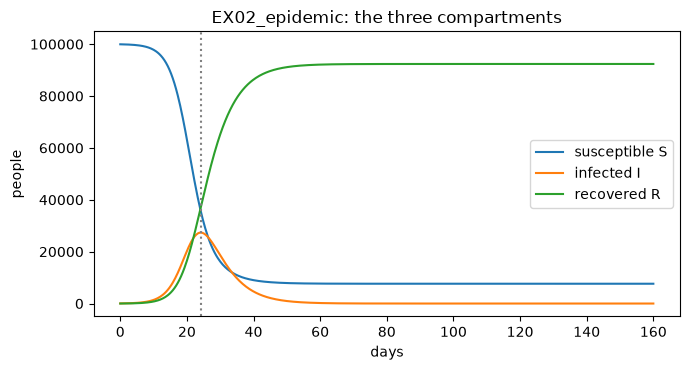

In [4]:
# draw the three compartments over the horizon, with the day of the infected peak
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(result.t, result.S, label="susceptible S")
ax.plot(result.t, result.I, label="infected I")
ax.plot(result.t, result.R, label="recovered R")
ax.axvline(result.t_peak, color="grey", linestyle=":")
ax.set_xlabel("days")
ax.set_ylabel("people")
ax.set_title("EX02_epidemic: the three compartments")
ax.legend()
fig.tight_layout()
plt.show()

The figure has the classic shape of an epidemic. The susceptible curve falls from almost the whole town to a small remainder, the recovered curve rises as its mirror image, and the infected curve is a single hump that peaks at the dotted line, about three and a half weeks in, and then falls back toward zero during the second month. What the figure does not show is any uncertainty: it is one deterministic run, with no randomness and no error bar, so the hump is exact only up to the engine's arithmetic, which the next notebook measures.

The engine also reports the three summary numbers itself, so there is no need to hunt for them in the curves. The cell prints them and then adds the three compartments at every step. An epidemic model that creates or loses people has a bug, so the sum has to stay at the population of 100000.

In [5]:
# the three summary numbers of the run, and the check that the compartments always add up to the population
print(f"peak {result.peak_I:.0f} people, on day {result.t_peak:.2f}")
print(f"attack rate {result.attack_rate:.4f}")
total = np.array(result.S) + np.array(result.I) + np.array(result.R)
print(f"S + I + R: {total.min():.1f} .. {total.max():.1f} (N = {p.N:.0f})")

peak 27345 people, on day 24.25
attack rate 0.9237
S + I + R: 100000.0 .. 100000.0 (N = 100000)


One case says little about the model. The next cell runs the engine on every case on file, including the control that starts with nobody infected, and prints the same three numbers for each, plus how many times the initial infected people the peak reaches. Look for how the numbers move with $\beta$ and $\gamma$, and for what the control does.

In [6]:
# the engine on every case, one line each, and the peak as a multiple of the first infected people
results = {}
for case_id in CASES:
    q = params_of(case_id)
    results[case_id] = simulate(q)
    r = results[case_id]
    print(f"{case_id:18s} peak {r.peak_I:7.0f}  on day {r.t_peak:6.2f}  attack rate {r.attack_rate:.4f}", end="  ")
    print(f"x{r.peak_I / max(q.I0, 1):6.1f}")

CTRL_degenerate    peak       0  on day   0.00  attack rate 0.0000  x   0.0
EX01_subcritical   peak      50  on day   0.00  attack rate 0.0018  x   1.0
EX02_epidemic      peak   27345  on day  24.25  attack rate 0.9237  x 546.9
EX03_fast_burn     peak   55265  on day   9.25  attack rate 0.9982  x 552.7
EX04_slow_spread   peak    1521  on day  96.25  attack rate 0.2993  x  30.4


The next cell draws the infected curves of the five cases, each as a share of its own population, so that their shapes can be compared.

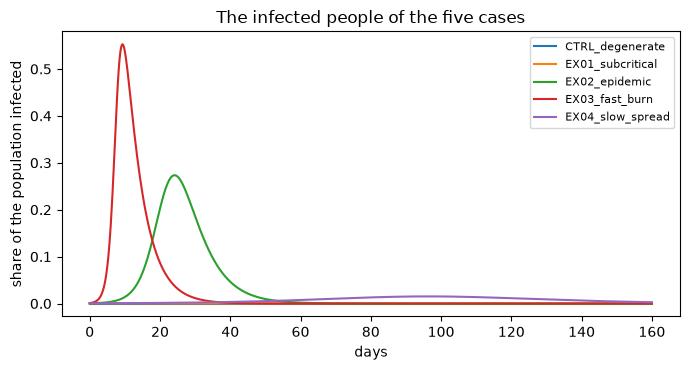

In [7]:
# draw the infected curves of the cases as a share of each population, to compare their shapes
fig, ax = plt.subplots(figsize=(7, 3.8))
for case_id, r in results.items():
    ax.plot(r.t, np.array(r.I) / params_of(case_id).N, label=case_id)
ax.set_xlabel("days")
ax.set_ylabel("share of the population infected")
ax.set_title("The infected people of the five cases")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The five curves share nothing but the horizon. The fast burn peaks early and high, a bit over half of the town ill at once; the epidemic case peaks about two weeks later and at half that height; the slow spread is a low, broad hump near day 96 that is still declining when the horizon ends. The sub-critical case never rises above its starting 50 people, and the control stays on the floor, so a model run with nobody infected correctly does nothing. The figure says nothing yet about why one case is fast and another slow: the second topic answers that with $R_0$.

Now one input at a time on the epidemic case. First the infected people on day 0: 50, then ten times and a hundred times as many. If the final toll is set by the disease and not by the match that lit it, the attack rate should barely move, while the timing should.

In [8]:
# change the first infected people to 10 and 100 times as many, with everything else as in the epidemic case
for factor in (1, 10, 100):
    q = replace(p, I0=p.I0 * factor)
    r = simulate(q)
    print(f"I0 = {q.I0:5.0f}  peak {r.peak_I:7.0f}  on day {r.t_peak:6.2f}  attack rate {r.attack_rate:.4f}")

I0 =    50  peak   27345  on day  24.25  attack rate 0.9237
I0 =   500  peak   27517  on day  17.25  attack rate 0.9241
I0 =  5000  peak   29235  on day  10.00  attack rate 0.9287


Second, how long a person stays infectious. The epidemic case has $\gamma = 0.20$, an infectious period of five days. Halving $\gamma$ makes it ten days with the same contact rate, so every infected person meets susceptible people for twice as long. The cell prints the product $\beta / \gamma$ next to the three numbers, because it is the quantity the second topic is built on.

In [9]:
# change the infectious period to 5 and to 10 days, which changes gamma and with it beta / gamma
for infectious_days in (5, 10):
    q = replace(p, gamma=1 / infectious_days)
    r = simulate(q)
    print(f"infectious period {infectious_days:2d} days  beta/gamma = {q.beta / q.gamma:4.2f}", end="  ")
    print(f"peak {r.peak_I:7.0f}  on day {r.t_peak:6.2f}  attack rate {r.attack_rate:.4f}")

infectious period  5 days  beta/gamma = 2.75  peak   27345  on day  24.25  attack rate 0.9237
infectious period 10 days  beta/gamma = 5.50  peak   51617  on day  21.25  attack rate 0.9963


## Results

**Answer:** In the epidemic case the worst moment is 27345 people ill at once, on day 24.25, and by the end of the 160 days 0.9237 of the town, almost 92.4 percent, has been infected. Starting with 500 or 5000 infected people instead of 50 moves the peak earlier, to day 17.25 and day 10.00, and raises the attack rate only from 0.9237 to 0.9241 and 0.9287, so the match that lights the outbreak sets its timing and hardly its size. A ten-day infectious period instead of five doubles $\beta / \gamma$ to 5.50, lifts the peak to 51617 people and brings the attack rate to 0.9963: the size does depend on the ratio.

The numbers describe a closed, homogeneous population with no vaccination, no distancing and no randomness, so they are what the equations imply and not a forecast of any real town. They also carry the engine's own arithmetic error, a few thousandths in the attack rate, which the next notebook quantifies. The figure of the five cases shows that the shape of the outbreak changes a great deal with $\beta$ and $\gamma$, but it does not yet tell which combination decides whether an outbreak happens at all.

## Summary

- One call of `simulate` returns the whole course of an outbreak: three curves and, derived from them, a peak, a peak day and an attack rate.
- The epidemic case peaks at 27345 infected on day 24.25 and ends with 0.9237 of the town infected.
- More first infected people bring the peak forward and leave the final size almost unchanged.
- A longer infectious period raises both the peak and the final size, through $\beta / \gamma$.
- Next: how accurate the engine's quarter-day arithmetic is, in notebook 02 of this topic.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Hethcote, H. W. (2000). The mathematics of infectious diseases. SIAM Review. https://doi.org/10.1137/S0036144500371907
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the cases of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).